# Step 6: Evaluation and diagnostics

**The only place final numbers are produced.** Steps 3a (baselines), 3b (Group 10 NRMS), 4 (deep hybrid, the main model) and 5 (its ablations) write prediction files to Drive; this notebook reads them, checks them, and computes every table, figure and number in the report with one evaluator (`shared/evaluator.py`, verified against a brute-force implementation in `tests/test_evaluator.py`). Nothing is trained here.

**To run:** Runtime → Run all (a CPU runtime is enough). It reads `MyDrive/BT4222_G11/features/v0.1/` and `MyDrive/BT4222_G11/predictions/real/`, and writes everything to `MyDrive/BT4222_G11/step6_outputs/real/` (cleared at the start of each run). The filled report is `step6_outputs/real/report_sections_filled.md`.

Rules (`docs/evaluation_spec.md`):

* Validation drove every choice; test (14 Nov) is read once for confirmation. Error analysis and the balance rule use validation.
* Cold at threshold *t* means fewer than *t* prior exposures at impression time. *t* = 10 is primary; 5 and 20 are sensitivity checks.
* Every interval is a 95% bootstrap over **users** (all impressions of a resampled user move together), paired across models on the same impressions.
* Every table carries its support (eligible impressions and clicks).

| Section | Report use |
|---|---|
| 1. Data support audit | Layer 0: is there enough cold data; threshold justification |
| 2. Prediction file checks | Reproducibility |
| 3. Headline table | Layers 1–2: baselines and NRMS vs the main model, train / val / test |
| 4. Threshold robustness | Cold vs warm at 5 / 10 / 20 |
| 5. Metric robustness, exposure | Layers 3–4: popularity-neutral metrics; who gets the first screen |
| 6. Balance | Layer 5: trade-off curve, slot-quota sweep, balance rule |
| 7. Ablation | Which component of the deep model is responsible |
| 8. Segments | For whom and when |
| 9. Stress slates | Secondary, resampled |
| 10. Error analysis | Why the model still fails |
| 11. Business numbers | Business insights |
| 12. Research question | Direct answer, parts 1 and 2 |
| 13. Export | Tables, figures, `report_numbers.json`, filled report sections |


## 0. Setup

In [1]:
import os, sys, subprocess, glob, json, time, warnings

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Bryng23/BT4222-Group-11.git"

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    REPO_DIR = "/content/BT4222-Group-11"
    if not os.path.exists(REPO_DIR):
        subprocess.run(["git", "clone", "-q", REPO_URL, REPO_DIR], check=True)
    DATA_ROOT = "/content/drive/MyDrive/BT4222_G11"
else:
    REPO_DIR = os.environ.get("G11_REPO_DIR", os.getcwd())
    DATA_ROOT = os.environ.get("G11_DATA_ROOT", os.path.join(REPO_DIR, "data"))
sys.path.insert(0, REPO_DIR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from shared import schema as S, feature_groups as FG
from shared import evaluator as E, segments as SG, audit as A, diagnostics as D, report_plots as P
from shared.predictions import read_predictions
from shared.report_io import Exporter

DATA_KIND = os.environ.get("G11_DATA_KIND", "REAL")       # SYNTHETIC only for local development
if DATA_KIND == "REAL":
    FEATURE_ROOT = os.path.join(DATA_ROOT, "features", f"v{S.SCHEMA_VERSION}")
else:
    FEATURE_ROOT = os.path.join(DATA_ROOT, "features", f"synthetic_v{S.SCHEMA_VERSION}", "learnable")
PRED_ROOT = os.path.join(DATA_ROOT, "predictions")
OUT_DIR = os.path.join(DATA_ROOT, "step6_outputs", DATA_KIND.lower())
version = S.read_version(FEATURE_ROOT)
assert version.get("data_kind", "REAL") == DATA_KIND, f"feature tables are {version.get('data_kind')}, run is {DATA_KIND}"

# ---- Frozen settings (docs/evaluation_spec.md) ----
READ_TEST = True                                          # every choice was frozen on validation; test is read once here
PRIMARY_T = S.PRIMARY_COLD                                 # 10
THRESHOLDS = S.COLD_THRESHOLDS                             # (5, 10, 20)
N_BOOT = int(os.environ.get("G11_N_BOOT", 1000))
BOOT_SEED = 0
QUOTAS = (0.0, 0.1, 0.2, 0.3)
MAX_WARM_DROP = (0.01, 0.02, 0.05)                         # tolerances x reported for the balance rule
STRESS = dict(slate_size=10, warm_share=0.4, seeds=(0, 1, 2))
ERROR_N = 30

SPLITS = ["train", "val"] + (["test"] if READ_TEST else [])
EVAL_SPLITS = [s for s in SPLITS if s != "train"]          # splits with intervals
REPORT_SPLIT = "test" if READ_TEST else "val"              # split shown in figures
# Ablation variants of the main deep model (step 5). CA = candidate-aware attention, IDM = ID masking,
# H = content smoothed CTR added as a feature. Every variant keeps the attention news and user encoders.
FG.ABLATIONS = {
    "full":                   ["T1", "T2", "T3", "U", "CA", "IDM"],
    "no_candidate_attention": ["T1", "T2", "T3", "U", "IDM"],
    "no_id_masking":          ["T1", "T2", "T3", "U", "CA"],
    "no_t1":                  ["T2", "T3", "U", "CA", "IDM"],
    "no_t2":                  ["T1", "T3", "U", "CA", "IDM"],
    "no_t3":                  ["T1", "T2", "U", "CA", "IDM"],
    "no_u":                   ["T1", "T2", "T3", "CA", "IDM"],
    "full_plus_smoothing":    ["T1", "T2", "T3", "U", "CA", "IDM", "H"],
}

import shutil
shutil.rmtree(OUT_DIR, ignore_errors=True)                 # outputs are regenerated in full on every run
P.setup_style()
X = Exporter(OUT_DIR)
print(f"DATA_KIND={DATA_KIND} | READ_TEST={READ_TEST} | splits={SPLITS} | n_boot={N_BOOT} | out={OUT_DIR}")

Mounted at /content/drive
DATA_KIND=REAL | READ_TEST=True | splits=['train', 'val', 'test'] | n_boot=1000 | out=/content/drive/MyDrive/BT4222_G11/step6_outputs/real


## 1. Data support audit (step 0: before any model is read)

Counts clicked cold candidates and cold-click impressions per split and threshold, and recomputes prior exposures from the row log to check the cold flags. The threshold justification uses **prior exposures at impression time** (what the cold flag uses), not total impressions over the window.

In [2]:
META_COLS = ["row_id", "impression_id", "user_id", "news_id", "time", "split", "label", "slate_size", "prior_exposures",
             "is_zero_exposure", "is_cold_5", "is_cold_10", "is_cold_20", "history_length", "category", "subcategory"]
meta = {}
for split in S.SPLITS:      # test meta has no model scores in it, so loading it for support counts is safe
    m = pd.read_parquet(S.meta_path(FEATURE_ROOT, split))
    meta[split] = m[[c for c in META_COLS if c in m.columns]].reset_index(drop=True)
meta_all = pd.concat([meta[s] for s in S.SPLITS], ignore_index=True)

structure = pd.DataFrame({s: A.check_meta(meta[s], s) for s in S.SPLITS}).T
X.table(structure, "audit_meta_structure", "Structural checks on the metadata tables")
display(structure)

flags = A.check_cold_flags(meta_all)
X.table(flags, "audit_cold_flags", "Stored prior_exposures and cold flags vs an independent recomputation")
display(flags.round(4))
if (flags["prior_exposures_agree"] < 0.999).any():
    warnings.warn("prior_exposures differ from the recomputation (strictly earlier timestamps, counted from the "
                  "start of the log). Check the counting rule before reading results.")

,rows,impressions,duplicate_row_id,duplicate_impression_news,impressions_without_click,impressions_all_clicked,slate_size_min,slate_size_max,labels_not_binary,slate_size_mismatch,rows_outside_split_window
train,3389342,95071,0,0,0,0,2,297,0,0,0
val,1231673,31624,0,0,0,0,2,299,0,0,0
test,1222429,30270,0,0,0,0,2,295,0,0,0


,rows,prior_exposures_agree,median_diff,max_abs_diff,is_cold_5_vs_stored_lt,is_cold_5_vs_recomputed_lt,is_cold_10_vs_stored_lt,is_cold_10_vs_recomputed_lt,is_cold_20_vs_stored_lt,is_cold_20_vs_recomputed_lt,is_zero_vs_stored
split,,,,,,,,,,,
test,1222429,1.0,0.0,0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
train,3389342,1.0,0.0,0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
val,1231673,1.0,0.0,0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [3]:
support = A.cold_support(meta)
X.table(support, "support_cold_clicks", "Cold-click support per split and threshold (cold = prior exposures < t)")
for (split, t), row in support.iterrows():
    X.number(f"support.{split}.t{t}.cold_click_impressions", int(row["cold_click_impressions"]), "{:,}")
    X.number(f"support.{split}.t{t}.cold_clicks", int(row["cold_clicks"]), "{:,}")
    X.number(f"support.{split}.t{t}.cold_click_share", row["cold_click_share"], "{:.1%}")
    X.number(f"support.{split}.t{t}.warm_click_share", 1 - row["cold_click_share"], "{:.1%}")
    X.number(f"support.{split}.t{t}.cold_row_share", row["cold_row_share"], "{:.1%}")
    X.number(f"support.{split}.t{t}.ci_halfwidth", row["ci_halfwidth_approx"], "{:.3f}")
display(support.round(4))
thin = support[support["cold_click_impressions"] < 300]
if len(thin):
    print("Fewer than 300 cold-click impressions (interval half-width above ~0.045):")
    display(thin[["cold_click_impressions", "ci_halfwidth_approx"]])

candidate_rows  impressions  cold_row_share  clicks  \
split threshold                                                        
train 5                 3389342        95071          0.0152  141558   
      10                3389342        95071          0.0250  141558   
      20                3389342        95071          0.0389  141558   
val   5                 1231673        31624          0.0106   47961   
      10                1231673        31624          0.0172   47961   
      20                1231673        31624          0.0268   47961   
test  5                 1222429        30270          0.0108   46825   
      10                1222429        30270          0.0180   46825   
      20                1222429        30270          0.0282   46825   

                 cold_clicks  cold_click_share  cold_click_impressions  \
split threshold                                                          
train 5                 2243            0.0158                    2064   
      10                3549            0.0251                    3223   
      20                5298            0.0374                    4721   
val   5                  620            0.0129                     586   
      10                1005            0.0210                     938   
      20                1543            0.0322                    1413   
test  5                  551            0.0118                     506   
      10                 912            0.0195                     837   
      20                1414            0.0302                    1276   

                 within_cold_impressions  zero_exposure_clicks  \
split threshold                                                  
train 5                             1351                   606   
      10                            2376                   606   
      20                            3690                   606   
val   5                              372                   168   
      10                             656                   168   
      20                            1063                   168   
test  5                              324                   148   
      10                             591                   148   
      20                             959                   148   

                 distinct_cold_clicked_articles  ci_halfwidth_approx  
split threshold                                                       
train 5                                    1980               0.0173  
      10                                   2791               0.0138  
      20                                   3572               0.0114  
val   5                                     532               0.0324  
      10                                    791               0.0256  
      20                                   1061               0.0209  
test  5                                     501               0.0349  
      10                                    747               0.0271  
      20                                    992               0.0219

,articles,share_reaching_t,median_hours_to_t,p75_hours_to_t,share_reaching_t_within_24h
threshold,,,,,
5,20288,0.604,2.284,5.116,0.599
10,20288,0.435,3.895,8.282,0.427
20,20288,0.305,5.271,10.342,0.299


,articles,mae,median_ae,binomial_sd,global_ctr,mae_relative_to_n1
n,,,,,,
1,2846,0.0668,0.0259,0.1970,0.0404,1.0000
2,2846,0.0624,0.0264,0.1393,0.0404,0.9339
3,2846,0.0571,0.0268,0.1137,0.0404,0.8549
5,2846,0.0526,0.0280,0.0881,0.0404,0.7878
7,2846,0.0484,0.0287,0.0745,0.0404,0.7250
10,2846,0.0435,0.0295,0.0623,0.0404,0.6510
15,2846,0.0369,0.0277,0.0509,0.0404,0.5519
20,2846,0.0328,0.0239,0.0441,0.0404,0.4910
30,2846,0.0276,0.0196,0.0360,0.0404,0.4135


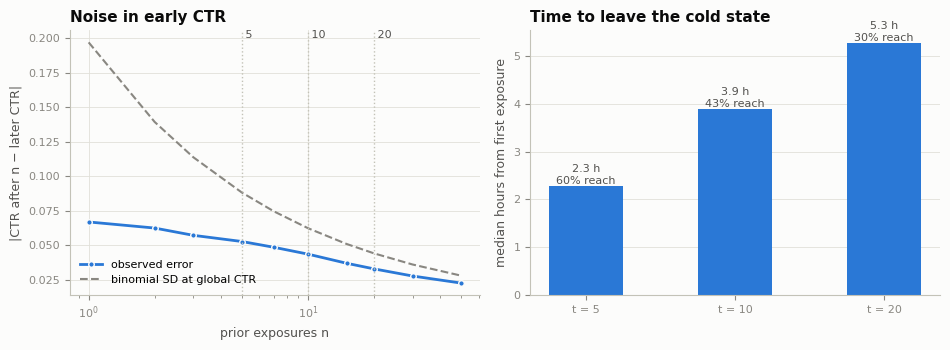

In [4]:
volume = A.threshold_volume(meta_all)
noise = A.ctr_noise_curve(meta_all)
X.table(volume, "threshold_volume", "Time and traffic needed to leave the cold state (prior exposures)")
X.table(noise, "threshold_noise_curve", "Error of early CTR as a predictor of later CTR, by prior exposures")
X.number("volume.median_exposures_per_article_day", volume.attrs["median_exposures_per_article_day"], "{:.0f}")
for t, row in volume.iterrows():
    X.number(f"volume.t{t}.median_hours", row["median_hours_to_t"], "{:.1f}")
    X.number(f"volume.t{t}.share_reaching", row["share_reaching_t"], "{:.1%}")
    X.number(f"volume.t{t}.share_within_24h", row["share_reaching_t_within_24h"], "{:.1%}")
for n in (5, 10, 20):
    if n in noise.index:
        X.number(f"noise.n{n}.mae", noise.loc[n, "mae"], "{:.4f}")
        X.number(f"noise.n{n}.rel", noise.loc[n, "mae_relative_to_n1"], "{:.2f}")
display(volume.round(3), noise.round(4))
fig = P.threshold_figure(noise, volume)
P.save(fig, X.figure_stem("fig_threshold_justification", "Threshold justification: early-CTR noise and time to warm"))
plt.show()

## 2. Prediction file inventory and checks

Only frozen choices are evaluated: files whose metadata say `selected_on = val`. Tuning-grid files are ignored. Every file is checked for row_id alignment, duplicates and finite scores before scoring; scores are joined to meta on `row_id`, never by position.

In [5]:
KIND = {"random": "baseline", "popularity": "baseline", "category_ctr": "baseline",
        "candidate_smoothed_ctr": "baseline", "content_smoothed_ctr": "baseline",
        "nrms_g10": "reference", "deep_hybrid": "main"}
REFERENCES = ["category_ctr", "candidate_smoothed_ctr", "nrms_g10"]   # every headline delta is against these
MAIN = "deep_hybrid"

def wanted(model_id):
    """Only the baselines, Group 10's NRMS, the main model and its ablation variants are evaluated."""
    return model_id in KIND or model_id.startswith("deep_")

inventory, files = [], {}
for path in sorted(glob.glob(os.path.join(PRED_ROOT, DATA_KIND.lower(), f"{DATA_KIND}__*.parquet"))):
    pred, info = read_predictions(path)
    if info.get("selected_on") != "val" or info.get("split") not in S.SPLITS or not wanted(info.get("model_id", "")):
        continue
    model_id, split = info["model_id"], info["split"]
    seed = info.get("seed")
    key = model_id if seed is None else f"{model_id}@seed{seed}"
    chk = A.check_predictions(meta[split], pred)
    inventory.append({"model": key, "split": split, "config_id": info["config_id"], "variant": info.get("variant"),
                      "schema": info.get("schema_version"), "created": info.get("created_utc"), **chk})
    if chk["ok"] and split in SPLITS:
        files[(key, split)] = path
inventory = pd.DataFrame(inventory).set_index(["model", "split"]).sort_index()
X.table(inventory.drop(columns=["created"]), "audit_prediction_files", "Prediction files read by step 6")
display(inventory)
bad = inventory[~inventory["ok"]]
assert bad.empty, f"prediction files failed checks:\n{bad}"
MODELS = sorted({m for m, _ in files})
def ablation_model(variant):
    return MAIN if variant == "full" else f"deep_{variant}"
ABLATION_MODELS = {ablation_model(v): v for v in FG.ABLATIONS if ablation_model(v) in MODELS}
print("models:", MODELS)
print("ablation variants:", list(ABLATION_MODELS.values()))
assert MAIN in MODELS, f"no {MAIN} prediction files in {os.path.join(PRED_ROOT, DATA_KIND.lower())}"

config_id  \
model                       split                                               
candidate_smoothed_ctr      test                                       beta=5   
                            train                                      beta=5   
                            val                                        beta=5   
category_ctr                test                                      default   
                            train                                     default   
                            val                                       default   
content_smoothed_ctr        test                                     alpha=20   
                            train                                    alpha=20   
                            val                                      alpha=20   
deep_full_plus_smoothing    test      full_plus_smoothing,id_mask=0.3,epoch=3   
                            val       full_plus_smoothing,id_mask=0.3,epoch=3   
deep_hybrid                 test                     full,id_mask=0.3,epoch=3   
                            train                    full,id_mask=0.3,epoch=3   
                            val                      full,id_mask=0.3,epoch=3   
deep_no_candidate_attention test   no_candidate_attention,id_mask=0.3,epoch=3   
                            train  no_candidate_attention,id_mask=0.3,epoch=3   
                            val    no_candidate_attention,id_mask=0.3,epoch=3   
deep_no_id_masking          test            no_id_masking,id_mask=0.0,epoch=1   
                            val             no_id_masking,id_mask=0.0,epoch=1   
deep_no_t1                  test                    no_t1,id_mask=0.3,epoch=3   
                            val                     no_t1,id_mask=0.3,epoch=3   
deep_no_t2                  test                    no_t2,id_mask=0.3,epoch=3   
                            val                     no_t2,id_mask=0.3,epoch=3   
deep_no_t3                  test                    no_t3,id_mask=0.3,epoch=3   
                            val                     no_t3,id_mask=0.3,epoch=3   
deep_no_u                   test                     no_u,id_mask=0.3,epoch=5   
                            val                      no_u,id_mask=0.3,epoch=5   
nrms_g10                    test                 heads=2,dropout=0.1,epoch=10   
                            train                heads=2,dropout=0.1,epoch=10   
                            val                  heads=2,dropout=0.1,epoch=10   
popularity                  test                                      default   
                            train                                     default   
                            val                                       default   
random                      test                                      default   
                            train                                     default   
                            val                                       default   

                                                  variant schema  \
model                       split                                  
candidate_smoothed_ctr      test                     None    0.1   
                            train                    None    0.1   
                            val                      None    0.1   
category_ctr                test                     None    0.1   
                            train                    None    0.1   
                            val                      None    0.1   
content_smoothed_ctr        test                     None    0.1   
                            train                    None    0.1   
                            val                      None    0.1   
deep_full_plus_smoothing    test      full_plus_smoothing    0.1   
                            val       full_plus_smoothing    0.1   
deep_hybrid                 test                     full    0.1   
                            train    

models: ['candidate_smoothed_ctr', 'category_ctr', 'content_smoothed_ctr', 'deep_full_plus_smoothing', 'deep_hybrid', 'deep_no_candidate_attention', 'deep_no_id_masking', 'deep_no_t1', 'deep_no_t2', 'deep_no_t3', 'deep_no_u', 'nrms_g10', 'popularity', 'random']
ablation variants: ['full', 'no_candidate_attention', 'no_id_masking', 'no_t1', 'no_t2', 'no_t3', 'no_u', 'full_plus_smoothing']


In [6]:
_score_cache = {}
def scores(model, split):
    if (model, split) not in _score_cache:
        pred, _ = read_predictions(files[(model, split)])
        _score_cache[(model, split)] = A.align_scores(meta[split], pred)
    return _score_cache[(model, split)]

_pi_cache = {}
def per_imp(model, split, t=PRIMARY_T):
    # per-impression table; cached for the primary threshold on val/test only (memory)
    key = (model, split, t)
    if key in _pi_cache:
        return _pi_cache[key]
    pi = E.per_impression_metrics(meta[split], scores(model, split), cold_threshold=t)
    if t == PRIMARY_T and split != "train":
        _pi_cache[key] = pi
    return pi

def has(model, split):
    return (model, split) in files

HEAD = ["auc", "mrr", "ndcg@5", "ndcg@10", "cold_recall@10", "cold_hit@10", "warm_recall@10", "zero_recall@10",
        "cold_auc_within", "cold_auc_vs_all", "cold_ndcg@10", "popdebiased_ndcg@10_g0.5", "popdebiased_ndcg@10_g1",
        "cold_slot_share@10", "cold_exposure_ratio@10", "novelty@10", "coverage@10",
        "cold_recall@10_lift", "warm_recall@10_lift"]
SUPPORT = ["n_impressions", "n_users", "n_clicks", "n_cold_click_impressions", "n_cold_clicks",
           "n_warm_click_impressions", "n_zero_click_impressions", "n_within_cold_impressions"]
DELTA_METRICS = ["ndcg@10", "auc", "cold_recall@10", "warm_recall@10", "cold_auc_within"]

## 3. Headline table: every model, train / validation / test

Train is shown because the report must give training and testing performance; for trained models the train numbers are in-sample. Deltas are model minus reference on the same impressions, with user-clustered intervals.

In [7]:
rows = []
for split in SPLITS:
    for model in MODELS:
        if not has(model, split):
            continue
        res = E.summarise(per_imp(model, split))
        res["coverage@10"] = E.catalogue_coverage(meta[split], scores(model, split))
        rows.append({"split": split, "model": model, "kind": KIND.get(model, "ablation" if model in ABLATION_MODELS else "other"),
                     **{k: res.get(k, np.nan) for k in HEAD + SUPPORT}})
        for k in HEAD:
            v = res.get(k, np.nan)
            X.number(f"{split}.{model}.{k}", v)
            X.number(f"{split}.{model}.{k}.per100", 100 * v, "{:.0f}")
headline = pd.DataFrame(rows).set_index(["split", "model"])
# strongest simple baseline, chosen on validation nDCG@10; exported under the alias "bestbase"
BEST_BASE = headline.loc["val"].query("kind == 'baseline'")["ndcg@10"].idxmax()
X.number("setting.best_baseline", BEST_BASE)
for split in SPLITS:
    if (split, BEST_BASE) in headline.index:
        for k in HEAD:
            v = headline.loc[(split, BEST_BASE), k]
            X.number(f"{split}.bestbase.{k}", v)
            X.number(f"{split}.bestbase.{k}.per100", 100 * v, "{:.0f}")
print("strongest simple baseline (validation nDCG@10):", BEST_BASE)
X.table(headline, "headline_all_models", f"All models, cold threshold {PRIMARY_T}; support columns give eligible impressions and clicks")
show = ["kind", "auc", "ndcg@10", "cold_recall@10", "warm_recall@10", "zero_recall@10", "cold_auc_within",
        "n_impressions", "n_cold_click_impressions"]
display(headline[show].round(4))

strongest simple baseline (validation nDCG@10): candidate_smoothed_ctr


kind     auc  ndcg@10  cold_recall@10  \
split model                                                                     
train candidate_smoothed_ctr        baseline  0.6784   0.4363          0.2809   
      category_ctr                  baseline  0.4822   0.2999          0.2287   
      content_smoothed_ctr          baseline  0.6799   0.4362          0.3211   
      deep_hybrid                       main  0.7557   0.5141          0.6672   
      deep_no_candidate_attention   ablation  0.7557   0.5140          0.6573   
      nrms_g10                     reference  0.7461   0.4988          0.6344   
      popularity                    baseline  0.4917   0.3174          0.0344   
      random                        baseline  0.5000   0.3071          0.2747   
val   candidate_smoothed_ctr        baseline  0.6434   0.3773          0.2932   
      category_ctr                  baseline  0.4903   0.2708          0.3324   
      content_smoothed_ctr          baseline  0.6449   0.3769          0.3701   
      deep_full_plus_smoothing      ablation  0.7154   0.4505          0.6843   
      deep_hybrid                       main  0.7163   0.4509          0.6875   
      deep_no_candidate_attention   ablation  0.7142   0.4495          0.6592   
      deep_no_id_masking            ablation  0.7074   0.4452          0.6888   
      deep_no_t1                    ablation  0.6817   0.4220          0.6800   
      deep_no_t2                    ablation  0.7162   0.4510          0.6753   
      deep_no_t3                    ablation  0.7113   0.4479          0.6795   
      deep_no_u                     ablation  0.6920   0.4265          0.6150   
      nrms_g10                     reference  0.6365   0.3829          0.5803   
      popularity                    baseline  0.4836   0.2755          0.0309   
      random                        baseline  0.5000   0.2779          0.2725   
test  candidate_smoothed_ctr        baseline  0.6468   0.3569          0.2489   
      category_ctr                  baseline  0.4977   0.2549          0.2979   
      content_smoothed_ctr          baseline  0.6479   0.3563          0.2694   
      deep_full_plus_smoothing      ablation  0.7097   0.4281          0.6375   
      deep_hybrid                       main  0.7095   0.4279          0.6268   
      deep_no_candidate_attention   ablation  0.7058   0.4249          0.5987   
      deep_no_id_masking            ablation  0.7036   0.4239          0.6223   
      deep_no_t1                    ablation  0.6615   0.3866          0.6510   
      deep_no_t2                    ablation  0.7092   0.4276          0.6196   
      deep_no_t3                    ablation  0.7053   0.4235          0.6143   
      deep_no_u                     ablation  0.6834   0.4027          0.6156   
      nrms_g10                     reference  0.6094   0.3439          0.5743   
      popularity                    baseline  0.4608   0.2405          0.0287   
      random                        baseline  0.5000   0.2623          0.2282   

                                   warm_recall@10  zero_recall@10  \
split model                                                         
train candidate_smoothed_ctr               0.6666          0.1364   
      category_ctr                         0.5275          0.2124   
      content_smoothed_ctr                 0.6662          0.2066   
      deep_hybrid                          0.7441          0.7028   
      deep_no_candidate_attention          0.7442          0.7034   
      nrms_g10                             0.7275          0.6533   
      popularity                           0.5435          0.0315   
      random                               0.5382          0.2337   
val   candidate_smoothed_ctr               0.6166          0.1758   
      category_ctr                         0.4984          0.3152   
      content_smoothed_ctr                 0.6162          0.2667   
      deep_full_plus_smoothing             0.6875          0.725

base   other   delta  ci_low  \
reference              metric                                            
category_ctr           ndcg@10          0.2549  0.4279  0.1730  0.1687   
                       auc              0.4977  0.7095  0.2118  0.2071   
                       cold_recall@10   0.2979  0.6268  0.3290  0.2935   
                       warm_recall@10   0.4808  0.6660  0.1852  0.1796   
                       cold_auc_within  0.4985  0.6475  0.1489  0.1055   
candidate_smoothed_ctr ndcg@10          0.3569  0.4279  0.0710  0.0677   
                       auc              0.6468  0.7095  0.0627  0.0593   
                       cold_recall@10   0.2489  0.6268  0.3779  0.3435   
                       warm_recall@10   0.5953  0.6660  0.0708  0.0654   
                       cold_auc_within  0.5496  0.6475  0.0979  0.0621   
nrms_g10               ndcg@10          0.3439  0.4279  0.0840  0.0805   
                       auc              0.6094  0.7095  0.1001  0.0965   
                       cold_recall@10   0.5743  0.6268  0.0526  0.0187   
                       warm_recall@10   0.5788  0.6660  0.0872  0.0825   
                       cold_auc_within  0.5920  0.6475  0.0555  0.0200   

                                        ci_high  n_impressions  
reference              metric                                   
category_ctr           ndcg@10           0.1772        30270.0  
                       auc               0.2163        30270.0  
                       cold_recall@10    0.3629          837.0  
                       warm_recall@10    0.1910        29945.0  
                       cold_auc_within   0.1903          591.0  
candidate_smoothed_ctr ndcg@10           0.0744        30270.0  
                       auc               0.0660        30270.0  
                       cold_recall@10    0.4156          837.0  
                       warm_recall@10    0.0757        29945.0  
                       cold_auc_within   0.1355          591.0  
nrms_g10               ndcg@10           0.0873        30270.0  
                       auc               0.1039        30270.0  
                       cold_recall@10    0.0886          837.0  
                       warm_recall@10    0.0922        29945.0  
                       cold_auc_within   0.0926          591.0

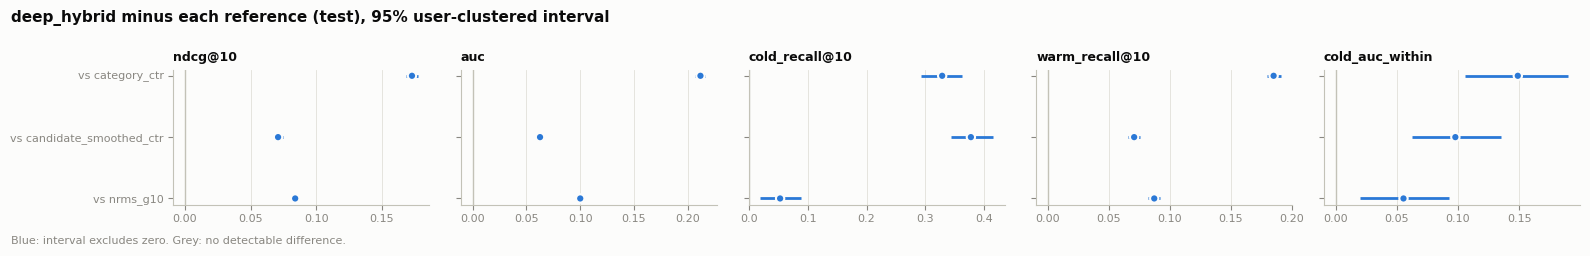

In [8]:
delta_rows = []
for split in EVAL_SPLITS:
    for model in [m for m in MODELS if KIND.get(m) in ("main", "reference", "baseline")]:
        for ref in REFERENCES:
            if model == ref or not (has(model, split) and has(ref, split)):
                continue
            d = E.compare(per_imp(ref, split), per_imp(model, split), DELTA_METRICS, n_boot=N_BOOT, seed=BOOT_SEED)
            for metric, r in d.iterrows():
                delta_rows.append({"split": split, "model": model, "reference": ref, "metric": metric, **r.to_dict()})
                stem = f"{split}.delta.{model}_vs_{ref}.{metric}"
                X.number(stem, r["delta"], "{:+.4f}")
                X.number(stem + ".ci", f"[{r['ci_low']:+.4f}, {r['ci_high']:+.4f}]")
                X.number(stem + ".per100", 100 * r["delta"], "{:+.1f}")
deltas = pd.DataFrame(delta_rows)
X.table(deltas.set_index(["split", "model", "reference", "metric"]), "headline_deltas",
        "Model minus reference, paired, 95% user-clustered bootstrap")
main_vs = deltas[(deltas["model"] == MAIN) & (deltas["split"] == REPORT_SPLIT)]
display(main_vs.set_index(["reference", "metric"])[["base", "other", "delta", "ci_low", "ci_high", "n_impressions"]].round(4))
if len(main_vs):
    fig = P.forest_plot(main_vs.assign(model=main_vs["reference"].map(lambda r: f"vs {r}")), label="model",
                        title=f"{MAIN} minus each reference ({REPORT_SPLIT}), 95% user-clustered interval")
    P.save(fig, X.figure_stem("fig_forest_main_vs_references", "Main model against the three references"))
    plt.show()

## 4. Threshold robustness: cold / warm / zero-exposure at t = 5, 10, 20

Same models, same scores; only the cold definition moves. A conclusion **survives** if the main-minus-reference delta on cold Recall@10 has the same sign at every threshold and its interval excludes zero at each.

In [9]:
COLS_T = ["cold_recall@10", "cold_hit@10", "warm_recall@10", "zero_recall@10", "cold_auc_within", "cold_ndcg@10",
          "n_cold_click_impressions", "n_cold_clicks", "n_within_cold_impressions"]
rob_rows, rob_delta = [], []
headline_models = [m for m in MODELS if KIND.get(m) in ("main", "reference", "baseline")]
for split in EVAL_SPLITS:
    for t in THRESHOLDS:
        pis = {m: per_imp(m, split, t) for m in headline_models if has(m, split)}
        for m, pi in pis.items():
            res = E.summarise(pi)
            rob_rows.append({"split": split, "threshold": t, "model": m, **{k: res.get(k) for k in COLS_T}})
        if MAIN in pis:
            for ref in REFERENCES:
                if ref in pis:
                    d = E.compare(pis[ref], pis[MAIN], ["cold_recall@10", "warm_recall@10"], n_boot=N_BOOT, seed=BOOT_SEED)
                    for metric, r in d.iterrows():
                        rob_delta.append({"split": split, "threshold": t, "reference": ref, "metric": metric, **r.to_dict()})
robust = pd.DataFrame(rob_rows).set_index(["split", "threshold", "model"])
robust_delta = pd.DataFrame(rob_delta)
X.table(robust, "threshold_robustness", "Cold, warm and zero-exposure metrics at thresholds 5, 10, 20")
display(robust.round(4))
if len(robust_delta):
    sig = (robust_delta["ci_low"] > 0) | (robust_delta["ci_high"] < 0)
    survive = (robust_delta.assign(sign=np.sign(robust_delta["delta"]), sig=sig)
               .groupby(["split", "reference", "metric"])
               .agg(signs=("sign", lambda s: "".join("+" if v > 0 else "-" for v in s)),
                    all_significant=("sig", "all"), same_sign=("sign", lambda s: s.nunique() == 1)))
    survive["survives"] = survive["all_significant"] & survive["same_sign"]
    X.table(robust_delta.set_index(["split", "threshold", "reference", "metric"]), "threshold_robustness_deltas",
            f"{MAIN} minus reference at each threshold")
    X.table(survive, "threshold_survival", "Which conclusions survive at 5, 10 and 20")
    display(survive)

cold_recall@10  cold_hit@10  \
split threshold model                                                 
val   5         candidate_smoothed_ctr          0.2333       0.2389   
                category_ctr                    0.3328       0.3362   
                content_smoothed_ctr            0.3485       0.3549   
                deep_hybrid                     0.7092       0.7184   
                nrms_g10                        0.5928       0.6075   
                popularity                      0.0256       0.0256   
                random                          0.2756       0.2833   
      10        candidate_smoothed_ctr          0.2932       0.3017   
                category_ctr                    0.3324       0.3380   
                content_smoothed_ctr            0.3701       0.3795   
                deep_hybrid                     0.6875       0.6972   
                nrms_g10                        0.5803       0.5949   
                popularity                      0.0309       0.0309   
                random                          0.2725       0.2814   
      20        candidate_smoothed_ctr          0.3389       0.3546   
                category_ctr                    0.3025       0.3100   
                content_smoothed_ctr            0.3739       0.3892   
                deep_hybrid                     0.6679       0.6829   
                nrms_g10                        0.5471       0.5655   
                popularity                      0.0340       0.0340   
                random                          0.2671       0.2781   
test  5         candidate_smoothed_ctr          0.1571       0.1660   
                category_ctr                    0.3050       0.3123   
                content_smoothed_ctr            0.2181       0.2273   
                deep_hybrid                     0.6430       0.6601   
                nrms_g10                        0.6150       0.6324   
                popularity                      0.0217       0.0217   
                random                          0.2266       0.2411   
      10        candidate_smoothed_ctr          0.2489       0.2593   
                category_ctr                    0.2979       0.3059   
                content_smoothed_ctr            0.2694       0.2784   
                deep_hybrid                     0.6268       0.6464   
                nrms_g10                        0.5743       0.5926   
                popularity                      0.0287       0.0287   
                random                          0.2282       0.2378   
      20        candidate_smoothed_ctr          0.3006       0.3158   
                category_ctr                    0.3029       0.3111   
                content_smoothed_ctr            0.3034       0.3174   
                deep_hybrid                     0.6189       0.6418   
                nrms_g10                        0.5517       0.5729   
                popularity                      0.0329       0.0329   
                random                          0.2411       0.2531   

                                        warm_recall@10  zero_recall@10  \
split threshold model                                                    
val   5         candidate_smoothed_ctr          0.6157          0.1758   
                category_ctr                    0.4983          0.3152   
                content_smoothed_ctr            0.6154          0.2667   
                deep_hybrid                     0.6865          0.7455   
                nrms_g10                        0.6191          0.6576   
                popularity                      0.4873          0.0364   
                random                          0.4988          0.2864   
      10        candidate_smoothed_ctr          0.6166          0.1758   
                category_ctr                    0.4984          0.3152   
                content_smoothed_ctr            0.6162          0.2667   
                deep_hybrid

signs  all_significant  same_sign  \
split reference              metric                                             
test  candidate_smoothed_ctr cold_recall@10   +++             True       True   
                             warm_recall@10   +++             True       True   
      category_ctr           cold_recall@10   +++             True       True   
                             warm_recall@10   +++             True       True   
      nrms_g10               cold_recall@10   +++            False       True   
                             warm_recall@10   +++             True       True   
val   candidate_smoothed_ctr cold_recall@10   +++             True       True   
                             warm_recall@10   +++             True       True   
      category_ctr           cold_recall@10   +++             True       True   
                             warm_recall@10   +++             True       True   
      nrms_g10               cold_recall@10   +++             True       True   
                             warm_recall@10   +++             True       True   

                                             survives  
split reference              metric                    
test  candidate_smoothed_ctr cold_recall@10      True  
                             warm_recall@10      True  
      category_ctr           cold_recall@10      True  
                             warm_recall@10      True  
      nrms_g10               cold_recall@10     False  
                             warm_recall@10      True  
val   candidate_smoothed_ctr cold_recall@10      True  
                             warm_recall@10      True  
      category_ctr           cold_recall@10      True  
                             warm_recall@10      True  
      nrms_g10               cold_recall@10      True  
                             warm_recall@10      True

## 5. Metric robustness: does the conclusion hold when popularity is removed?

Plain nDCG mixes cold and warm and rewards popular items. The same comparison is repeated with metrics that do not: within-cold AUC (no warm item to lean on), cold-only nDCG, and popularity-debiased nDCG (click gain weighted by 1 / (prior exposures + 1)^γ, γ = 0.5 and 1).

In [10]:
ROBUST_METRICS = ["ndcg@10", "auc", "cold_recall@10", "cold_auc_within", "cold_auc_vs_all", "cold_ndcg@10",
                  "popdebiased_ndcg@10_g0.5", "popdebiased_ndcg@10_g1", "cold_slot_share@10"]
mr = []
for split in EVAL_SPLITS:
    for ref in REFERENCES:
        if has(MAIN, split) and has(ref, split):
            d = E.compare(per_imp(ref, split), per_imp(MAIN, split), ROBUST_METRICS, n_boot=N_BOOT, seed=BOOT_SEED)
            mr.append(d.reset_index().assign(split=split, reference=ref))
metric_robust = pd.concat(mr, ignore_index=True) if mr else pd.DataFrame()
if len(metric_robust):
    metric_robust["verdict"] = np.select([metric_robust["ci_low"] > 0, metric_robust["ci_high"] < 0],
                                         ["main better", "main worse"], "no detectable difference")
    X.table(metric_robust.set_index(["split", "reference", "metric"]), "metric_robustness",
            f"{MAIN} minus reference under each metric family")
    display(metric_robust.pivot_table(index="metric", columns=["split", "reference"], values="verdict", aggfunc="first"))

split                                      test                            \
reference                candidate_smoothed_ctr category_ctr     nrms_g10   
metric                                                                      
auc                                 main better  main better  main better   
cold_auc_vs_all                     main better  main better  main better   
cold_auc_within                     main better  main better  main better   
cold_ndcg@10                        main better  main better  main better   
cold_recall@10                      main better  main better  main better   
cold_slot_share@10                  main better  main better   main worse   
ndcg@10                             main better  main better  main better   
popdebiased_ndcg@10_g0.5            main better  main better  main better   
popdebiased_ndcg@10_g1              main better  main better  main better   

split                                       val               \
reference                candidate_smoothed_ctr category_ctr   
metric                                                         
auc                                 main better  main better   
cold_auc_vs_all                     main better  main better   
cold_auc_within                     main better  main better   
cold_ndcg@10                        main better  main better   
cold_recall@10                      main better  main better   
cold_slot_share@10                  main better  main better   
ndcg@10                             main better  main better   
popdebiased_ndcg@10_g0.5            main better  main better   
popdebiased_ndcg@10_g1              main better  main better   

split                                               
reference                                 nrms_g10  
metric                                              
auc                                    main better  
cold_auc_vs_all                        main better  
cold_auc_within                        main better  
cold_ndcg@10                           main better  
cold_recall@10                         main better  
cold_slot_share@10        no detectable difference  
ndcg@10                                main better  
popdebiased_ndcg@10_g0.5               main better  
popdebiased_ndcg@10_g1                 main better

### 5b. Layer 4: who gets exposure (the rich-get-richer loop)

Articles are grouped by how often they were shown in the split: the most-shown 1%, the middle, and the least-shown 80%. *Logged* is the share of all impressions MSN gave each group; each model column is the share of top-10 slots it would give them.

In [11]:
split = REPORT_SPLIT
conc_models = list(dict.fromkeys(m for m in [MAIN, "nrms_g10", BEST_BASE, "candidate_smoothed_ctr", "popularity", "random"]
                                 if has(m, split)))
conc = D.exposure_concentration(meta[split], {m: scores(m, split) for m in conc_models})
X.table(conc, "exposure_concentration", f"Share of exposure by article popularity group ({split}): logged vs each model's top 10")
for col in conc.columns:
    for idx, name in zip(conc.index, ["top", "middle", "bottom"]):
        X.number(f"conc.{split}.{col}.{name}", conc.loc[idx, col], "{:.1%}")
        if col == BEST_BASE:
            X.number(f"conc.{split}.bestbase.{name}", conc.loc[idx, col], "{:.1%}")
display(conc.round(4))

,logged,deep_hybrid,nrms_g10,candidate_smoothed_ctr,popularity,random
top 1% of articles,0.3680,0.4989,0.5380,0.6703,0.7726,0.5222
middle,0.5992,0.4625,0.4268,0.3080,0.2241,0.4553
bottom 80% of articles,0.0328,0.0386,0.0352,0.0217,0.0033,0.0226


## 6. Balance: the cold-vs-warm trade-off

Not sacrificing warm articles to help cold ones. Three pieces of evidence:

1. Every model and ablation as a point (warm Recall@10, cold Recall@10).
2. A **slot-quota re-ranker** on saved scores: reserve q = 0, 10, 20, 30% of the top 10 for the best-scoring cold candidates. No retraining.
3. A **balance rule**: maximise cold Recall@10 subject to warm Recall@10 ≥ (1 − x) × the best baseline's warm Recall@10, for x = 1, 2 and 5%. Computed on validation.


cold_recall@10  warm_recall@10  ndcg@10  \
model                quota                                            
deep_hybrid          0.0            0.6875          0.6856   0.4509   
                     0.1            0.7642          0.6835   0.4506   
                     0.2            0.8326          0.6811   0.4502   
                     0.3            0.8746          0.6795   0.4498   
nrms_g10             0.0            0.5803          0.6184   0.3829   
                     0.1            0.7045          0.6159   0.3828   
                     0.2            0.8015          0.6137   0.3826   
                     0.3            0.8573          0.6122   0.3825   
content_smoothed_ctr 0.0            0.3701          0.6162   0.3769   
                     0.1            0.5846          0.6120   0.3769   
                     0.2            0.7452          0.6093   0.3770   
                     0.3            0.8365          0.6074   0.3768   

                            cold_slot_share@10  zero_recall@10  
model                quota                                      
deep_hybrid          0.0                0.0225          0.7455  
                     0.1                0.0309          0.7939  
                     0.2                0.0391          0.8061  
                     0.3                0.0456          0.8485  
nrms_g10             0.0                0.0222          0.6576  
                     0.1                0.0310          0.7424  
                     0.2                0.0392          0.8212  
                     0.3                0.0458          0.8636  
content_smoothed_ctr 0.0                0.0119          0.2667  
                     0.1                0.0259          0.4424  
                     0.2                0.0370          0.6182  
                     0.3                0.0448          0.7273

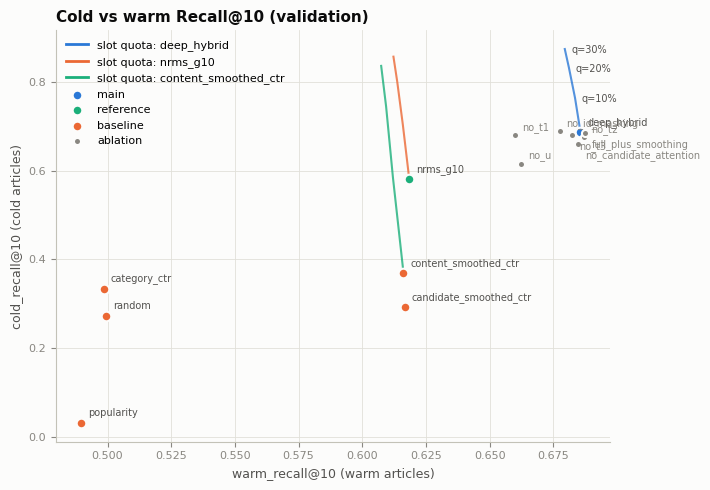

In [12]:
split = "val"
pts = headline.loc[split].reset_index()[["model", "kind", "cold_recall@10", "warm_recall@10", "ndcg@10"]]
curves, sweeps = {}, {}
for m in [MAIN, "nrms_g10", "content_smoothed_ctr"]:
    if has(m, split):
        tab, _ = D.quota_sweep(meta[split], scores(m, split), QUOTAS, PRIMARY_T)
        sweeps[m], curves[m] = tab, tab
sweep_table = pd.concat({m: t[["cold_recall@10", "warm_recall@10", "ndcg@10", "cold_slot_share@10", "zero_recall@10"]]
                         for m, t in sweeps.items()}, names=["model", "quota"])
X.table(sweep_table, "balance_quota_sweep", "Slot-quota re-ranking on validation (q = share of top-10 reserved for cold)")
display(sweep_table.round(4))

fig = P.tradeoff_plot(pts, curves, title="Cold vs warm Recall@10 (validation)")
P.save(fig, X.figure_stem("fig_tradeoff_val", "Cold-vs-warm trade-off with slot-quota curves"))
plt.show()

In [13]:
baselines = pts[pts["kind"] == "baseline"].set_index("model")
REF_WARM_MODEL = baselines["warm_recall@10"].idxmax()
ref_warm = baselines.loc[REF_WARM_MODEL, "warm_recall@10"]
candidates = pd.concat([pts.set_index("model")[["cold_recall@10", "warm_recall@10"]]] +
                       [t[["cold_recall@10", "warm_recall@10"]].rename(index=lambda q, m=m: f"{m} q={q:.0%}")
                        for m, t in sweeps.items()])
candidates["pareto"] = D.pareto_front(candidates)
rule = pd.DataFrame([{"max_warm_drop": x, "warm_floor": ref_warm * (1 - x),
                      "selected": D.balance_select(candidates, ref_warm, x)} for x in MAX_WARM_DROP])
rule = rule.merge(candidates, left_on="selected", right_index=True, how="left")
print(f"warm reference: best baseline on validation = {REF_WARM_MODEL} (warm Recall@10 {ref_warm:.4f})")
X.table(rule.set_index("max_warm_drop"), "balance_rule", "Balance rule: highest cold Recall@10 with warm Recall@10 within x of the best baseline")
X.table(candidates, "balance_candidates", "All models and quota settings, with Pareto flag (validation)")
for _, r in rule.iterrows():
    tag = f"balance.x{int(round(r['max_warm_drop'] * 100))}"
    X.number(f"{tag}.selected", r["selected"])
    X.number(f"{tag}.cold", r["cold_recall@10"])
    X.number(f"{tag}.warm", r["warm_recall@10"])
X.number("balance.ref_model", REF_WARM_MODEL)
X.number("balance.ref_warm", ref_warm)
if MAIN in sweeps:
    for q, r in sweeps[MAIN].iterrows():
        tag = f"balance.quota{int(round(q * 100))}"
        X.number(f"{tag}.cold", r["cold_recall@10"])
        X.number(f"{tag}.warm", r["warm_recall@10"])
        X.number(f"{tag}.cold.per100", 100 * r["cold_recall@10"], "{:.0f}")
        X.number(f"{tag}.warm.per100", 100 * r["warm_recall@10"], "{:.0f}")
display(rule.round(4))

warm reference: best baseline on validation = candidate_smoothed_ctr (warm Recall@10 0.6166)


,max_warm_drop,warm_floor,selected,cold_recall@10,warm_recall@10,pareto
0,0.01,0.6105,deep_hybrid q=30%,0.8746,0.6795,True
1,0.02,0.6043,deep_hybrid q=30%,0.8746,0.6795,True
2,0.05,0.5858,deep_hybrid q=30%,0.8746,0.6795,True


## 7. Ablation analysis (main deep model)

Each step 5 variant is the main model retrained from scratch with one change; the attention news and user encoders are in every variant.

* **Leave-one-out** (`no_*`): full minus one component (T1, T2, T3, U, candidate-aware attention CA, ID masking IDM). A drop means the component carried information the others could not replace.
* **Add-on** (`full_plus_smoothing`): content smoothed CTR added as a feature.
* Components overlap (content reaches the model through the news encoder as well as T2, T3 and U), so contributions do not add up.
* **Decision rule**: a component "helps cold articles" only if removing it lowers cold Recall@10 with the validation interval below zero and the test delta has the same sign. Otherwise "no detectable effect".


In [14]:
tiers = D.tier_matrix([v for v in FG.ABLATIONS])
tiers["prediction files"] = [ablation_model(v) in MODELS for v in tiers.index]
X.table(tiers.replace({True: "✓", False: ""}), "ablation_variants", "Ablation variants and their feature groups")
display(tiers)

ABL_METRICS = ["ndcg@10", "cold_recall@10", "warm_recall@10", "cold_auc_within", "zero_recall@10"]
abl_level, abl_delta = [], []
for split in EVAL_SPLITS:
    pis = {v: per_imp(m, split) for m, v in ABLATION_MODELS.items() if has(m, split)}
    for v, pi in pis.items():
        res = E.summarise(pi)
        abl_level.append({"split": split, "variant": v, **D.describe_variant(v),
                          **{k: res[k] for k in ABL_METRICS}, "cold_click_impressions": res["n_cold_click_impressions"]})
    if "full" in pis:
        d = D.ablation_deltas(pis, "full", ABL_METRICS, n_boot=N_BOOT, seed=BOOT_SEED)
        abl_delta.append(d.assign(split=split))
    if "u_only" in pis:
        d = D.ablation_deltas({k: v for k, v in pis.items() if k.endswith("_only") or k == "u_only"}, "u_only",
                              ABL_METRICS, n_boot=N_BOOT, seed=BOOT_SEED)
        abl_delta.append(d.assign(split=split))
abl_level = pd.DataFrame(abl_level).set_index(["split", "variant"])
abl_delta = pd.concat(abl_delta, ignore_index=True) if abl_delta else pd.DataFrame()
X.table(abl_level, "ablation_levels", "Ablation variants: metric levels and cold-click support")
display(abl_level.round(4))

,CA,H,IDM,T1,T2,T3,U,prediction files
full,True,False,True,True,True,True,True,True
no_candidate_attention,False,False,True,True,True,True,True,True
no_id_masking,True,False,False,True,True,True,True,True
no_t1,True,False,True,False,True,True,True,True
no_t2,True,False,True,True,False,True,True,True
no_t3,True,False,True,True,True,False,True,True
no_u,True,False,True,True,True,True,False,True
full_plus_smoothing,True,True,True,True,True,True,True,True


kind groups  ndcg@10  cold_recall@10  \
split variant                                                             
val   full                         base          0.4509          0.6875   
      no_candidate_attention  leave-out     CA   0.4495          0.6592   
      no_id_masking           leave-out    IDM   0.4452          0.6888   
      no_t1                   leave-out     T1   0.4220          0.6800   
      no_t2                   leave-out     T2   0.4510          0.6753   
      no_t3                   leave-out     T3   0.4479          0.6795   
      no_u                    leave-out      U   0.4265          0.6150   
      full_plus_smoothing        add-on      H   0.4505          0.6843   
test  full                         base          0.4279          0.6268   
      no_candidate_attention  leave-out     CA   0.4249          0.5987   
      no_id_masking           leave-out    IDM   0.4239          0.6223   
      no_t1                   leave-out     T1   0.3866          0.6510   
      no_t2                   leave-out     T2   0.4276          0.6196   
      no_t3                   leave-out     T3   0.4235          0.6143   
      no_u                    leave-out      U   0.4027          0.6156   
      full_plus_smoothing        add-on      H   0.4281          0.6375   

                              warm_recall@10  cold_auc_within  zero_recall@10  \
split variant                                                                   
val   full                            0.6856           0.6689          0.7455   
      no_candidate_attention          0.6847           0.6780          0.7152   
      no_id_masking                   0.6774           0.6736          0.7515   
      no_t1                           0.6599           0.6513          0.7273   
      no_t2                           0.6872           0.6621          0.7273   
      no_t3                           0.6824           0.6692          0.7500   
      no_u                            0.6623           0.6206          0.5924   
      full_plus_smoothing             0.6875           0.6732          0.7258   
test  full                            0.6660           0.6475          0.7063   
      no_candidate_attention          0.6614           0.6329          0.6515   
      no_id_masking                   0.6591           0.6365          0.7413   
      no_t1                           0.6268           0.6467          0.6655   
      no_t2                           0.6648           0.6455          0.7273   
      no_t3                           0.6610           0.6329          0.6795   
      no_u                            0.6390           0.6121          0.6469   
      full_plus_smoothing             0.6649           0.6531          0.7179   

                              cold_click_impressions  
split variant                                         
val   full                                       938  
      no_candidate_attention                     938  
      no_id_masking                              938  
      no_t1                                      938  
      no_t2                                      938  
      no_t3                                      938  
      no_u                                       938  
      full_plus_smoothing                        938  
test  full                                       837  
      no_candidate_attention                     837  
      no_id_masking                              837  
      no_t1                                      837  
      no_t2                                      837  
      no_t3                                      837  
      no_u                                       837  
      full_plus_smoothing                        837

,tier removed,val delta,val CI,test delta,decision
variant,,,,,
no_candidate_attention,CA,-0.028252,"[-0.0436, -0.0145]",-0.028176,tier helps cold
no_id_masking,IDM,0.001333,"[-0.0160, +0.0194]",-0.004580,no detectable effect
no_t1,T1,-0.007463,"[-0.0316, +0.0166]",0.024194,no detectable effect
no_t2,T2,-0.012171,"[-0.0294, +0.0036]",-0.007268,no detectable effect
no_t3,T3,-0.007907,"[-0.0254, +0.0104]",-0.012545,no detectable effect
no_u,U,-0.072406,"[-0.1004, -0.0444]",-0.011250,tier helps cold


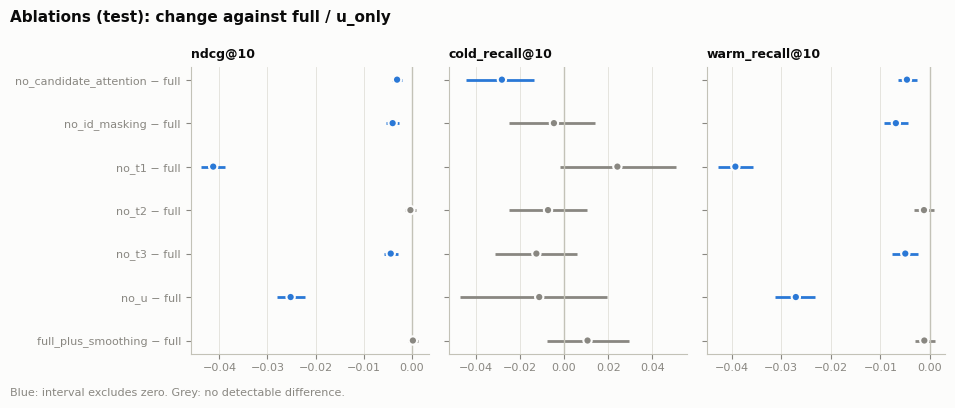

In [15]:
if len(abl_delta):
    main_tab = abl_delta[abl_delta["against"] == "full"].pivot_table(
        index=["split", "variant"], columns="metric", values=["delta", "ci_low", "ci_high"])
    X.table(abl_delta.set_index(["split", "against", "variant", "metric"]), "ablation_deltas",
            "Variant minus full (leave-one-out) and minus u_only (add-one-in), user-clustered 95% intervals")
    for _, r in abl_delta.iterrows():
        stem = f"ablation.{r['split']}.{r['variant']}_vs_{r['against']}.{r['metric']}"
        X.number(stem, r["delta"], "{:+.4f}")
        X.number(stem + ".ci", f"[{r['ci_low']:+.4f}, {r['ci_high']:+.4f}]")
    # decision rule on leave-one-out rows
    cr = abl_delta[(abl_delta["metric"] == "cold_recall@10") & (abl_delta["against"] == "full")].set_index(["variant", "split"])
    dec = []
    for v in sorted({i[0] for i in cr.index}):
        info = D.describe_variant(v)
        if info["kind"] != "leave-out" or (v, "val") not in cr.index:
            continue
        val = cr.loc[(v, "val")]
        test_delta = cr.loc[(v, "test"), "delta"] if (v, "test") in cr.index else None
        dec.append({"variant": v, "tier removed": info["groups"], "val delta": val["delta"],
                    "val CI": f"[{val['ci_low']:+.4f}, {val['ci_high']:+.4f}]",
                    "test delta": test_delta, "decision": D.decision(val["ci_low"], val["ci_high"], test_delta)})
        X.number(f"ablation.{v}.decision", dec[-1]["decision"])
        X.number(f"ablation.{v}.val_delta", val["delta"], "{:+.4f}")
    decisions = pd.DataFrame(dec).set_index("variant") if dec else pd.DataFrame()
    X.table(decisions, "ablation_decisions", "Pre-registered decision rule applied to cold Recall@10")
    display(decisions)
    d = abl_delta[abl_delta["split"] == REPORT_SPLIT].assign(model=lambda t: t["variant"] + " − " + t["against"])
    fig = P.forest_plot(d[d["metric"].isin(["ndcg@10", "cold_recall@10", "warm_recall@10"])],
                        title=f"Ablations ({REPORT_SPLIT}): change against full / u_only")
    P.save(fig, X.figure_stem("fig_ablation_forest", "Ablation deltas with user-clustered intervals"))
    plt.show()

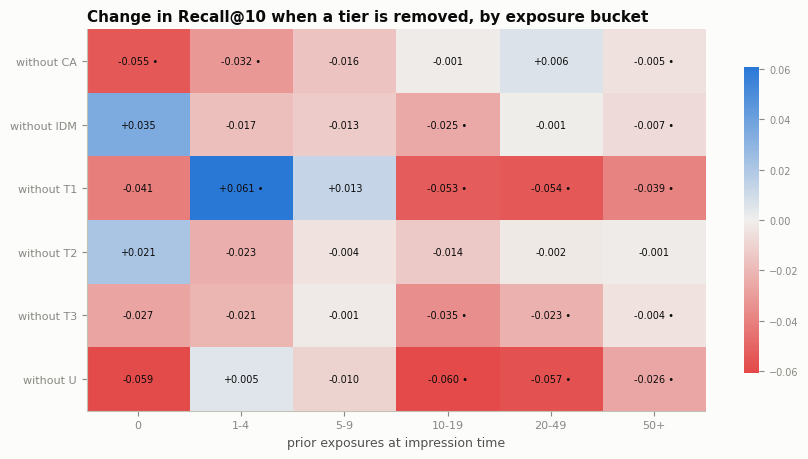

In [16]:
# Where each component matters: change in Recall@10 by prior-exposure bucket when a tier is removed.
split = REPORT_SPLIT
heat, lo, hi, heat_by_variant = {}, {}, {}, {}
if has(MAIN, split):
    _, long_full = SG.evaluate_by(meta[split], scores(MAIN, split), by="exposure", return_long=True)
    for m, v in ABLATION_MODELS.items():
        info = D.describe_variant(v)
        if info["kind"] != "leave-out" or not has(m, split):
            continue
        _, long_v = SG.evaluate_by(meta[split], scores(m, split), by="exposure", return_long=True)
        sd = SG.segment_deltas(long_full, long_v, "recall@10", n_boot=N_BOOT, seed=BOOT_SEED)
        label = f"without {info['groups']}"
        heat[label], lo[label], hi[label] = sd["delta"], sd["ci_low"], sd["ci_high"]
        heat_by_variant[v] = sd
if heat:
    order = SG.EXPOSURE_LABELS
    H = pd.DataFrame(heat).T.reindex(columns=order)
    L_, U_ = pd.DataFrame(lo).T.reindex(columns=order), pd.DataFrame(hi).T.reindex(columns=order)
    X.table(H, "ablation_heatmap_values", f"Change in Recall@10 by exposure bucket when a tier is removed ({split})")
    fig = P.ablation_heatmap(H, L_, U_)
    P.save(fig, X.figure_stem("fig_ablation_heatmap", "Tier removed × exposure bucket"))
    plt.show()

In [17]:
# Training noise: spread across seeds, when step 5 writes seeded files (info["seed"]); otherwise state single-seed.
seeded = sorted({m for m in MODELS if "@seed" in m})
if seeded:
    rows = []
    for m in seeded:
        base, seed = m.split("@seed")
        for split in EVAL_SPLITS:
            if has(m, split):
                res = E.summarise(per_imp(m, split))
                rows.append({"variant": base, "seed": seed, "split": split, **{k: res[k] for k in ABL_METRICS}})
    spread = D.seed_spread(pd.DataFrame(rows), ABL_METRICS, by=["split", "variant"])
    X.table(spread, "ablation_seed_spread", "Spread across training seeds")
    display(spread.round(4))
else:
    print("No seeded prediction files: every model is single-seed. State this as a limitation.")

No seeded prediction files: every model is single-seed. State this as a limitation.


## 8. Segment diagnostics

Candidate-level segments (exposure bucket, category): Recall@10 of clicked candidates in the segment, in full slates. Impression-level segments (user history, slate length, hour): every metric within the segment. Lift is over a random ranker on the same impressions, which makes segments with different slate lengths comparable.

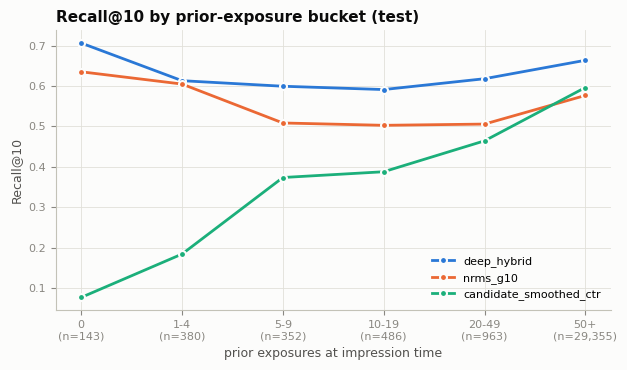

eligible_impressions  clicks  candidates  \
model                  exposure                                             
deep_hybrid            5-9                        352     361        8725   
                       20-49                      963    1008       25878   
                       50+                      29355   44403     1162093   
                       10-19                      486     502       12485   
                       1-4                        380     403        9937   
                       0                          143     148        3311   
nrms_g10               5-9                        352     361        8725   
                       20-49                      963    1008       25878   
                       50+                      29355   44403     1162093   
                       10-19                      486     502       12485   
                       1-4                        380     403        9937   
                       0                          143     148        3311   
candidate_smoothed_ctr 5-9                        352     361        8725   
                       20-49                      963    1008       25878   
                       50+                      29355   44403     1162093   
                       10-19                      486     502       12485   
                       1-4                        380     403        9937   
                       0                          143     148        3311   
content_smoothed_ctr   5-9                        352     361        8725   
                       20-49                      963    1008       25878   
                       50+                      29355   44403     1162093   
                       10-19                      486     502       12485   
                       1-4                        380     403        9937   
                       0                          143     148        3311   
category_ctr           5-9                        352     361        8725   
                       20-49                      963    1008       25878   
                       50+                      29355   44403     1162093   
                       10-19                      486     502       12485   
                       1-4                        380     403        9937   
                       0                          143     148        3311   
popularity             5-9                        352     361        8725   
                       20-49                      963    1008       25878   
                       50+                      29355   44403     1162093   
                       10-19                      486     502       12485   
                       1-4                        380     403        9937   
                       0                          143     148        3311   

                                 recall@5  recall@5_lift   hit@5  recall@10  \
model                  exposure                                               
deep_hybrid            5-9         0.4616         0.3223  0.4659     0.5994   
                       20-49       0.4683         0.2858  0.4787     0.6180   
                       50+         0.4900         0.1786  0.5703     0.6636   
                       10-19       0.4249         0.2826  0.4300     0.5912   
                       1-4         0.4518         0.3234  0.4658     0.6132   
                       0           0.5291         0.4083  0.5385     0.7063   
nrms_g10               5-9         0.3736         0.2342  0.3750     0.5085   
                       20-49       0.3583         0.1758  0.3666     0.5058   
                       50+         0.3967         0.0852  0.4616     0.5766   
                       10-19       0.3323         0.1900  0.3354     0.5027   
                       1-4         0.4289         0.3006  0.4395     0.6048   
                       0           0.4918         0.3710  0.5035     0.6352   


In [18]:
split = REPORT_SPLIT
SEG_MODELS = list(dict.fromkeys(m for m in (MAIN, "nrms_g10", BEST_BASE, "content_smoothed_ctr", "category_ctr", "popularity")
                                if has(m, split)))
seg_tables = {}
for by in ("exposure", "category"):
    t = pd.concat({m: SG.evaluate_by(meta[split], scores(m, split), by=by) for m in SEG_MODELS}, names=["model"])
    seg_tables[by] = t
    X.table(t, f"segment_{by}", f"Recall@10 of clicked candidates by {by} ({split})")
for by in ("history", "slate", "hour"):
    t = pd.concat({m: SG.evaluate_by(meta[split], scores(m, split), by=by, per_imp=per_imp(m, split),
                                     metrics=["ndcg@10", "auc", "cold_recall@10", "warm_recall@10", "cold_recall@10_lift"])
                   for m in SEG_MODELS}, names=["model"])
    seg_tables[by] = t
    X.table(t, f"segment_{by}", f"Metrics by {by} bucket ({split})")

for by, t in seg_tables.items():
    col = "recall@10" if by in ("exposure", "category") else "cold_recall@10"
    for (m, b), v in t[col].items():
        X.number(f"{split}.seg.{by}.{str(b).replace(' ', '_')}.{'bestbase' if m == BEST_BASE else m}.{col}", v)
        if m == BEST_BASE:
            X.number(f"{split}.seg.{by}.{str(b).replace(' ', '_')}.{m}.{col}", v)
exp = seg_tables["exposure"]["recall@10"].unstack("model").reindex(SG.EXPOSURE_LABELS)
supp = seg_tables["exposure"].xs(SEG_MODELS[0], level="model")["eligible_impressions"]
fig = P.metric_by_bucket(exp[SEG_MODELS[:3]], support=supp, title=f"Recall@10 by prior-exposure bucket ({split})")
P.save(fig, X.figure_stem("fig_recall_by_exposure", "Recall@10 by exposure bucket, top models"))
plt.show()
display(seg_tables["exposure"].round(4))

## 9. Stress slates (secondary result, resampled)

Every impression is rebuilt as a 10-candidate slate with a fixed mix (40% warm, 60% cold), keeping every click and sampling unclicked candidates. This tests whether the ranking holds when cold articles are not a small minority. Three sampling seeds; impressions that cannot meet the mix are dropped and counted. Valid because all models score candidates pointwise. **Label it as resampled in the report.**

In [19]:
split = REPORT_SPLIT
cold = E.cold_mask(meta[split], PRIMARY_T)
stress_rows, stress_info = [], []
for seed in STRESS["seeds"]:
    mask, info = D.stress_slate_mask(meta[split], cold, STRESS["slate_size"], STRESS["warm_share"], seed)
    stress_info.append(info)
    sub = meta[split][mask].reset_index(drop=True)
    for m in [x for x in MODELS if KIND.get(x) in ("main", "reference", "baseline") and has(x, split)]:
        res = E.evaluate(sub, scores(m, split)[mask], cold_threshold=PRIMARY_T)
        stress_rows.append({"seed": seed, "model": m, **{k: res[k] for k in ["ndcg@10", "auc", "cold_recall@5",
                            "warm_recall@5", "cold_auc_within", "cold_auc_vs_all", "n_impressions"]}})
stress = pd.DataFrame(stress_rows).groupby("model").agg(["mean", "std"])
X.table(stress, "stress_slates", f"Stress slates ({split}, resampled): 10 candidates, 40% warm; mean and SD over 3 seeds")
X.table(pd.DataFrame(stress_info), "stress_slates_info", "Stress-slate construction: impressions kept")
display(pd.DataFrame(stress_info), stress.round(4))

,slate_size,warm_share,seed,impressions_in,impressions_kept,share_kept,rows_kept
0,10,0.4,0,30270,832,0.027486,8320
1,10,0.4,1,30270,832,0.027486,8320
2,10,0.4,2,30270,832,0.027486,8320


seed      ndcg@10             auc          \
                       mean  std    mean     std    mean     std   
model                                                              
candidate_smoothed_ctr  1.0  1.0  0.6386  0.0040  0.6364  0.0052   
category_ctr            1.0  1.0  0.5414  0.0012  0.4655  0.0017   
content_smoothed_ctr    1.0  1.0  0.6321  0.0034  0.5961  0.0044   
deep_hybrid             1.0  1.0  0.6178  0.0012  0.5837  0.0032   
nrms_g10                1.0  1.0  0.5555  0.0031  0.5286  0.0027   
popularity              1.0  1.0  0.7150  0.0037  0.7954  0.0021   
random                  1.0  1.0  0.5330  0.0009  0.5000  0.0000   

                       cold_recall@5         warm_recall@5          \
                                mean     std          mean     std   
model                                                                
candidate_smoothed_ctr        0.4892  0.0317        0.6886  0.0051   
category_ctr                  0.5709  0.0060        0.4247  0.0068   
content_smoothed_ctr          0.5764  0.0146        0.6166  0.0055   
deep_hybrid                   0.7527  0.0047        0.5628  0.0053   
nrms_g10                      0.7080  0.0194        0.5063  0.0020   
popularity                    0.1456  0.0176        1.0000  0.0000   
random                        0.4926  0.0200        0.4947  0.0028   

                       cold_auc_within         cold_auc_vs_all          \
                                  mean     std            mean     std   
model                                                                    
candidate_smoothed_ctr          0.5415  0.0080          0.5473  0.0160   
category_ctr                    0.5184  0.0032          0.5316  0.0015   
content_smoothed_ctr            0.5656  0.0026          0.5911  0.0055   
deep_hybrid                     0.6546  0.0087          0.7054  0.0039   
nrms_g10                        0.5963  0.0125          0.6387  0.0100   
popularity                      0.4996  0.0081          0.3417  0.0070   
random                          0.5000  0.0000          0.5000  0.0000   

                       n_impressions       
                                mean  std  
model                                      
candidate_smoothed_ctr         832.0  0.0  
category_ctr                   832.0  0.0  
content_smoothed_ctr           832.0  0.0  
deep_hybrid                    832.0  0.0  
nrms_g10                       832.0  0.0  
popularity                     832.0  0.0  
random                         832.0  0.0

## 10. Error analysis (validation, main model)

Three groups of cold candidates: clicked and ranked in the top 3 (**success**), clicked and ranked in the bottom quarter (**failure**), and unclicked but ranked in the top 3 (**false alarm**). Patterns are computed on all cases; the 30 sampled rows per group are for reading titles. Run on validation so test stays unread for anything but confirmation.

In [20]:
split = "val"
ATTR_COLS = ["row_id", "entity_count", "entity_embedding_coverage", "article_age_hours", "prior_ctr", "recent_exposures_6h",
             "category_recent_ctr_6h", "subcategory_recent_ctr_6h", "entity_recent_ctr_mean_6h", "semantic_neighbor_ctr",
             "text_similarity", "entity_similarity", "category_affinity", "subcategory_affinity"]
import pyarrow.parquet as pq
feat_cols = pq.read_schema(S.features_path(FEATURE_ROOT, split)).names
attrs = pd.read_parquet(S.features_path(FEATURE_ROOT, split), columns=[c for c in ATTR_COLS if c in feat_cols])
news = None
try:     # titles and abstracts from the raw MIND files, when available
    if DATA_KIND == "REAL":
        import kagglehub
        RAW_DIR = os.path.join(kagglehub.dataset_download("arashnic/mind-news-dataset"), "MINDsmall_train")
    else:
        RAW_DIR = os.path.join(FEATURE_ROOT, "raw")
    news = pd.read_csv(os.path.join(RAW_DIR, "news.tsv"), sep="\t", header=None, quoting=3,
                       names=["news_id", "cat", "subcat", "title", "abstract", "url", "te", "ae"])[["news_id", "title", "abstract"]]
    news["abstract_present"] = news["abstract"].fillna("").str.len().gt(0).astype(float)
    news["title_length"] = news["title"].fillna("").str.split().str.len()
except Exception as exc:
    print("raw news.tsv not available, titles skipped:", exc)

cases = D.error_cases(meta[split], scores(MAIN, split), E.cold_mask(meta[split], PRIMARY_T), attrs)
if news is not None:
    cases = cases.merge(news, on="news_id", how="left")
patterns = D.compare_cases(cases)
X.table(patterns["numeric"], "error_patterns_numeric", f"Error analysis ({MAIN}, {split}): attributes by case, all cases")
if "category" in patterns:
    X.table(patterns["category"], "error_patterns_category", "Category mix by case")
samples = D.sample_cases(cases, ERROR_N)
pd.concat(samples, names=["case"]).to_csv(os.path.join(X.tables_dir, "error_samples.csv"))
for c, n in cases["case"].value_counts().items():
    X.number(f"error.{c}.count", int(n), "{:,}")
tierpat = D.tier_patterns(cases)
X.table(tierpat, "error_patterns_by_tier", "Which evidence differs between failures and successes, grouped by tier "
        "(std_diff = standardised mean difference, failure minus success; |0.2| or more is flagged)")
notable = tierpat[tierpat["notable"]]
for i in range(1, 4):
    X.number(f"error.pattern{i}", f"{notable.iloc[i - 1]['reading']} [{notable.iloc[i - 1]['tier']}]"
             if len(notable) >= i else "no further notable difference")
for tier in D.TIER_ATTRS:
    X.number(f"error.tier.{tier.split()[0]}.notable", int(notable["tier"].eq(tier).sum()))
display(tierpat.round(3))
display(patterns["numeric"].round(3))
display(patterns.get("category", pd.DataFrame()).round(3))
for name, s in samples.items():
    print(f"--- {name}: {D.CASES[name]}")
    display(s[[c for c in ("rank", "slate_size", "category", "prior_exposures", "title") if c in s.columns]].head(10))

100%|██████████| 61.7M/61.7M [00:00<00:00, 73.0MB/s]

Extracting files...


,tier,attribute,mean false_alarm,mean success,mean failure,std_diff,notable,reading
0,U user matching,text_similarity,0.329,0.359,0.108,-2.277,True,failure cases have lower text similarity to th...
1,U user matching,category_affinity,0.334,0.391,0.025,-2.190,True,failure cases have lower reader's affinity for...
2,U user matching,subcategory_affinity,0.154,0.212,0.000,-1.574,True,failure cases have lower reader's affinity for...
3,T1 own behaviour,prior_exposures,3.306,3.565,6.556,1.130,True,failure cases have higher prior exposures than...
4,T1 own behaviour,recent_exposures_6h,3.101,3.368,6.111,1.045,True,failure cases have higher exposures in the las...
5,U user matching,entity_similarity,0.538,0.576,0.307,-1.030,True,failure cases have lower entity similarity to ...
6,T1 own behaviour,prior_ctr,0.110,0.129,0.000,-0.830,True,failure cases have lower prior CTR than succes...
7,T2 borrowed behaviour,subcategory_recent_ctr_6h,0.044,0.049,0.031,-0.806,True,failure cases have lower recent CTR of its sub...
8,T1 own behaviour,article_age_hours,2.084,2.038,5.588,0.676,True,failure cases have higher article age (hours) ...
9,T2 borrowed behaviour,semantic_neighbor_ctr,0.052,0.067,0.025,-0.501,True,failure cases have lower CTR of similar articl...


n slate_size        history_length        prior_exposures  \
                        mean median           mean median            mean   
case                                                                        
failure         9     64.778   42.0         42.667   50.0           6.556   
false_alarm  2089     57.031   48.0         39.036   24.0           3.306   
success       356     43.801   33.0         42.983   26.0           3.565   

                   entity_count        article_age_hours         \
            median         mean median              mean median   
case                                                              
failure        7.0        2.333    2.0             5.588  2.730   
false_alarm    3.0        2.494    2.0             2.084  0.839   
success        3.0        2.708    2.0             2.038  0.975   

            abstract_present        title_length           hour         
                        mean median         mean median    mean median  
case                                                                    
failure                0.889    1.0       11.222   10.0  13.556   12.0  
false_alarm            0.892    1.0       10.887   10.0  11.419   11.0  
success                0.907    1.0       10.879   10.0  10.876   11.0

case,failure,false_alarm,success
category,,,
sports,0.222,0.361,0.466
news,0.222,0.343,0.351
lifestyle,0.222,0.037,0.014
tv,0.111,0.009,0.014
foodanddrink,0.111,0.047,0.031
finance,0.111,0.044,0.031


--- failure: clicked cold candidate ranked in the bottom quarter of its slate


,rank,slate_size,category,prior_exposures,title
2408,22,26,foodanddrink,9,27 bad eating habits you need to stop right now
592,134,165,news,3,Trump impeachment hearing spurs shadow spin war
590,129,165,news,4,Chris Wallace: Impeachment witness William Tay...
1441,2,2,tv,4,Here's Why There's Already Backlash About the ...
2433,34,43,finance,9,50 Work-From-Home Jobs Paying as Much or a Lot...
2257,21,23,lifestyle,7,9 Amazing Transgender Women Who Changed History
1378,67,85,sports,9,Purple & Bold: Being a Lakers fan in 2019 mean...
455,35,42,lifestyle,7,Meghan Markle and Prince Harry Won't Spend Chr...
1594,27,32,sports,7,Pittsburghers Celebrate World Kindness Day By ...


--- false_alarm: unclicked cold candidate ranked in the top 3


,rank,slate_size,category,prior_exposures,title
462,1,80,travel,4,Suspicious package at company near Tampa Inter...
266,1,43,news,1,Worcester fire lieutenant killed in early morn...
161,1,54,sports,2,Cleveland failed to score on seven straight pl...
433,1,30,sports,9,Can we stop with the Rob Gronkowski comeback t...
28,1,24,news,3,4 top spots for pizza in Cleveland
409,1,15,video,0,At least five suspects caught robbing Nike sto...
187,1,85,news,4,"SC man stabbed wife, pregnant stepdaughter to ..."
366,1,41,sports,0,Links: Tigers make big organizational moves
332,1,55,news,0,"75-year-old man repeatedly punched, robbed ins..."
306,1,44,news,8,Guaido backers enter Venezuela embassy in Bras...


--- success: clicked cold candidate ranked in the top 3


,rank,slate_size,category,prior_exposures,title
19,3,19,foodanddrink,3,These Are America's Favorite Liquor Brands
824,3,29,news,1,Top Miami news: City postpones vote on next st...
2020,1,50,news,3,The 4 best florists in Miami
1457,1,4,tv,7,Here's Why There's Already Backlash About the ...
512,1,117,travel,6,Arrest made after fire at iconic Beefy King re...
1550,1,58,news,3,Florida Has 15 Best STEM High Schools: Newsweek
661,1,13,finance,1,Microsoft Wins the Pentagon JEDI Contract
315,2,24,music,1,Dirt bikes and pyro can't save the Chainsmoker...
210,2,25,news,3,A Milwaukee man was fatally stabbed on the wes...
1982,3,41,news,0,"Hart Island, Final Resting Place Of 1 Million,..."


## 11. Business numbers

Only claims backed by a number above. Clicked cold articles placed in the top 10, per 1,000 impressions, against the strongest reference, and the warm cost. These are offline counts on logged slates: they say how the ranking would have ordered articles users did click, not how many extra clicks a live system would get.

In [21]:
split = REPORT_SPLIT
biz = []
for ref in dict.fromkeys(REFERENCES + [BEST_BASE]):
    if has(MAIN, split) and has(ref, split):
        b = D.business_impact(per_imp(ref, split), per_imp(MAIN, split), n_boot=N_BOOT, seed=BOOT_SEED)
        biz.append(b.reset_index().assign(model=MAIN, reference=ref))
        for metric, r in b.iterrows():
            for name in [ref] + (["bestbase"] if ref == BEST_BASE else []):
                X.number(f"business.{split}.{MAIN}_vs_{name}.{metric}", r["delta_per_1000"], "{:+.1f}")
                X.number(f"business.{split}.{MAIN}_vs_{name}.{metric}.ci",
                         f"[{r['ci_low']:+.1f}, {r['ci_high']:+.1f}]")
                X.number(f"business.{split}.{name}.{metric}.base", r["base_per_1000"], "{:.1f}")
            X.number(f"business.{split}.{MAIN}.{metric}.level", r["model_per_1000"], "{:.1f}")
if has(MAIN, split) and MAIN in sweeps:
    for q in QUOTAS[1:]:
        _, pis = D.quota_sweep(meta[split], scores(MAIN, split), (q,), PRIMARY_T)
        b = D.business_impact(per_imp(MAIN, split), pis[q], n_boot=N_BOOT, seed=BOOT_SEED)
        biz.append(b.reset_index().assign(model=f"{MAIN} q={q:.0%}", reference=MAIN))
        for metric, r in b.iterrows():
            X.number(f"business.{split}.quota{int(round(q * 100))}.{metric}", r["delta_per_1000"], "{:+.1f}")
business = pd.concat(biz, ignore_index=True) if biz else pd.DataFrame()
if len(business):
    X.table(business.set_index(["model", "reference", "metric"]), "business_clicks_per_1000",
            f"Clicked articles in the top 10 per 1,000 impressions ({split}); offline counts")
    display(business.round(2))

# which categories gain most (cold Recall@10 by category, main vs best baseline by validation nDCG@10)
best_base = BEST_BASE
_, la = SG.evaluate_by(meta[split].assign(cat_cold=np.where(E.cold_mask(meta[split], PRIMARY_T), meta[split]["category"], None)),
                       scores(best_base, split), by="cat_cold", return_long=True)
_, lb = SG.evaluate_by(meta[split].assign(cat_cold=np.where(E.cold_mask(meta[split], PRIMARY_T), meta[split]["category"], None)),
                       scores(MAIN, split), by="cat_cold", return_long=True)
cat_gain = SG.segment_deltas(la, lb, "recall@10", n_boot=N_BOOT, seed=BOOT_SEED).sort_values("delta", ascending=False)
X.table(cat_gain, "business_category_gain", f"Cold Recall@10 gain by category, {MAIN} minus {best_base} ({split})")
if len(cat_gain):
    X.number(f"business.{split}.top_category", cat_gain.index[0])
    X.number(f"business.{split}.top_category.gain", cat_gain["delta"].iloc[0], "{:+.3f}")
    X.number(f"business.{split}.top_category.gain.per100", 100 * cat_gain["delta"].iloc[0], "{:+.0f}")
    X.number(f"business.{split}.top_category.ci", f"[{cat_gain['ci_low'].iloc[0]:+.3f}, {cat_gain['ci_high'].iloc[0]:+.3f}]")
    X.number(f"business.{split}.weakest_category", cat_gain.index[-1])
    X.number(f"business.{split}.weakest_category.gain", cat_gain["delta"].iloc[-1], "{:+.3f}")
    X.number(f"business.{split}.n_categories_gain", int((cat_gain["ci_low"] > 0).sum()))
    X.number(f"business.{split}.n_categories_loss", int((cat_gain["ci_high"] < 0).sum()))
    X.number(f"business.{split}.n_categories", len(cat_gain))
display(cat_gain.round(4))

,metric,base_per_1000,model_per_1000,delta_per_1000,ci_low,ci_high,se,n_impressions,n_clusters,model,reference
0,n_cold_hits@10,8.46,18.63,10.18,8.84,11.54,0.66,30270,20179,deep_hybrid,category_ctr
1,n_warm_hits@10,595.80,890.85,295.04,286.42,304.29,4.54,30270,20179,deep_hybrid,category_ctr
2,n_zero_hits@10,1.29,3.47,2.18,1.65,2.76,0.29,30270,20179,deep_hybrid,category_ctr
3,n_cold_hits@10,7.27,18.63,11.36,10.14,12.73,0.67,30270,20179,deep_hybrid,candidate_smoothed_ctr
4,n_warm_hits@10,786.36,890.85,104.49,97.20,111.79,3.74,30270,20179,deep_hybrid,candidate_smoothed_ctr
5,n_zero_hits@10,0.36,3.47,3.11,2.48,3.76,0.33,30270,20179,deep_hybrid,candidate_smoothed_ctr
6,n_cold_hits@10,16.98,18.63,1.65,0.60,2.69,0.55,30270,20179,deep_hybrid,nrms_g10
7,n_warm_hits@10,750.45,890.85,140.40,132.99,147.91,3.76,30270,20179,deep_hybrid,nrms_g10
8,n_zero_hits@10,3.11,3.47,0.36,-0.03,0.79,0.21,30270,20179,deep_hybrid,nrms_g10
9,n_cold_hits@10,18.63,21.24,2.61,2.05,3.21,0.29,30270,20179,deep_hybrid q=10%,deep_hybrid


/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


,delta,ci_low,ci_high,eligible_impressions
segment,,,,
video,0.5417,0.3529,0.7500,24
sports,0.4674,0.3996,0.5359,261
weather,0.4583,0.2067,0.6875,24
finance,0.4500,0.2618,0.6316,40
news,0.3645,0.3065,0.4247,310
health,0.3478,0.1111,0.5653,23
autos,0.3333,0.1667,0.5001,29
lifestyle,0.2927,0.0978,0.4857,41
movies,0.2857,0.0000,0.6667,7


## 12. Answering the research question

> *Does combining T1, T2 and T3 improve personalised ranking for under-exposed articles, and how does each tier's contribution differ between cold and warm articles?*

**Part 1, the combination.** The main model (content and history encoders + T1, T2, T3, U) against the references: the best simple baseline (behaviour only) and Group 10's NRMS (content only). A verdict needs the interval to exclude zero.

**Part 2, each component.** Contribution = main model minus the model retrained without it, so **positive means it helps**. Read the cold and warm columns side by side. "Helps most at" is the exposure bucket where removing it costs the most Recall@10.


In [22]:
split = REPORT_SPLIT
RQ_METRICS = ["cold_recall@10", "warm_recall@10", "zero_recall@10", "cold_auc_within", "ndcg@10"]
others = [r for r in dict.fromkeys(REFERENCES + [BEST_BASE]) if has(r, split)]
part1 = []
for other in (others if has(MAIN, split) else []):
    d = E.compare(per_imp(other, split), per_imp(MAIN, split), RQ_METRICS, n_boot=N_BOOT, seed=BOOT_SEED)
    verdict = D.tradeoff_verdict(d.loc["cold_recall@10", "ci_low"], d.loc["cold_recall@10", "ci_high"],
                                 d.loc["warm_recall@10", "ci_low"], d.loc["warm_recall@10", "ci_high"])
    row = {"combined model vs": other, "verdict": verdict}
    aliases = [other] + (["bestbase"] if other == BEST_BASE else [])
    for m, r in d.iterrows():
        row[f"Δ {m}"] = r["delta"]
        row[f"{m} CI"] = f"[{r['ci_low']:+.4f}, {r['ci_high']:+.4f}]"
        for a in aliases:
            X.number(f"rq.vs_{a}.{m}", r["delta"], "{:+.4f}")
            X.number(f"rq.vs_{a}.{m}.ci", row[f"{m} CI"])
            X.number(f"rq.vs_{a}.{m}.per100", 100 * r["delta"], "{:+.1f}")
    for a in aliases:
        X.number(f"rq.vs_{a}.verdict", verdict)
    part1.append(row)
part1 = pd.DataFrame(part1).set_index("combined model vs") if part1 else pd.DataFrame()
X.table(part1, "rq_part1_combination", f"RQ part 1 ({split}): full model minus each comparison, 95% user-clustered intervals")
display(part1)

contrib = D.tier_contributions(abl_delta, split, metrics=RQ_METRICS) if len(abl_delta) else pd.DataFrame()
for v in contrib.index:
    g = contrib.loc[v, "group removed"]
    if v in heat_by_variant:
        gain = (-heat_by_variant[v]["delta"]).dropna()
        if len(gain):
            contrib.loc[v, "helps most at exposures"] = gain.idxmax()
            contrib.loc[v, "contribution there"] = gain.max()
            X.number(f"rq.tier.{g}.peak_bucket", gain.idxmax())
            X.number(f"rq.tier.{g}.peak_gain", gain.max(), "{:+.3f}")
    for m in RQ_METRICS:
        if f"{m} contribution" in contrib.columns and pd.notna(contrib.loc[v, f"{m} contribution"]):
            c = contrib.loc[v]
            X.number(f"rq.tier.{g}.{m}", c[f"{m} contribution"], "{:+.4f}")
            X.number(f"rq.tier.{g}.{m}.ci", f"[{c[f'{m} ci_low']:+.4f}, {c[f'{m} ci_high']:+.4f}]")
            X.number(f"rq.tier.{g}.{m}.per100", 100 * c[f"{m} contribution"], "{:+.1f}")
            X.number(f"rq.tier.{g}.{m}.reading", c[f"{m} reading"])
if len(contrib):
    X.table(contrib, "rq_part2_tier_contributions",
            f"RQ part 2 ({split}): what each group adds = full minus the model without it (positive = helps)")
    show = ["group removed"] + [f"{m} {x}" for m in ("cold_recall@10", "warm_recall@10", "zero_recall@10")
                                for x in ("contribution", "reading")] + \
           [c for c in ("helps most at exposures", "contribution there") if c in contrib.columns]
    display(contrib[[c for c in show if c in contrib.columns]].round(4))

# one-line plain-English summary per question
summary = []
if len(part1) and BEST_BASE in part1.index:
    summary.append({"question": f"Does the combined model rank clicked cold articles higher than the best simple baseline ({BEST_BASE})?",
                    "answer": part1.loc[BEST_BASE, "verdict"]})
for v in contrib.index:
    c = contrib.loc[v]
    summary.append({"question": f"What does {c['group removed']} add?",
                    "answer": f"cold: {c.get('cold_recall@10 reading', 'n/a')}; warm: {c.get('warm_recall@10 reading', 'n/a')}"
                              + (f"; matters most at {c['helps most at exposures']} prior exposures"
                                 if pd.notna(c.get("helps most at exposures")) else "")})
summary = pd.DataFrame(summary)
X.table(summary, "rq_summary_plain", "Research question in one line per part")
display(summary)

,verdict,Δ cold_recall@10,cold_recall@10 CI,Δ warm_recall@10,warm_recall@10 CI,Δ zero_recall@10,zero_recall@10 CI,Δ cold_auc_within,cold_auc_within CI,Δ ndcg@10,ndcg@10 CI
combined model vs,,,,,,,,,,,
category_ctr,better for cold articles; better for warm arti...,0.328953,"[+0.2935, +0.3629]",0.185219,"[+0.1796, +0.1910]",0.437063,"[+0.3516, +0.5216]",0.148936,"[+0.1055, +0.1903]",0.172955,"[+0.1687, +0.1772]"
candidate_smoothed_ctr,better for cold articles; better for warm arti...,0.377937,"[+0.3435, +0.4156]",0.070767,"[+0.0654, +0.0757]",0.629371,"[+0.5513, +0.7080]",0.097887,"[+0.0621, +0.1355]",0.070979,"[+0.0677, +0.0744]"
nrms_g10,better for cold articles; better for warm arti...,0.052569,"[+0.0187, +0.0886]",0.087250,"[+0.0825, +0.0922]",0.071096,"[-0.0068, +0.1521]",0.055490,"[+0.0200, +0.0926]",0.084012,"[+0.0805, +0.0873]"


,group removed,cold_recall@10 contribution,cold_recall@10 reading,warm_recall@10 contribution,warm_recall@10 reading,zero_recall@10 contribution,zero_recall@10 reading,helps most at exposures,contribution there
variant,,,,,,,,,
no_candidate_attention,CA,0.0282,helps,0.0047,helps,0.0548,helps,0,0.0548
no_id_masking,IDM,0.0046,no detectable effect,0.0069,helps,-0.0350,no detectable effect,10-19,0.0254
no_t1,T1,-0.0242,no detectable effect,0.0392,helps,0.0408,no detectable effect,20-49,0.0543
no_t2,T2,0.0073,no detectable effect,0.0012,no detectable effect,-0.0210,no detectable effect,1-4,0.0232
no_t3,T3,0.0125,no detectable effect,0.0050,helps,0.0268,no detectable effect,10-19,0.0346
no_u,U,0.0113,no detectable effect,0.0270,helps,0.0594,no detectable effect,10-19,0.0597


,question,answer
0,Does the combined model rank clicked cold arti...,better for cold articles; better for warm arti...
1,What does CA add?,cold: helps; warm: helps; matters most at 0 pr...
2,What does IDM add?,cold: no detectable effect; warm: helps; matte...
3,What does T1 add?,cold: no detectable effect; warm: helps; matte...
4,What does T2 add?,cold: no detectable effect; warm: no detectabl...
5,What does T3 add?,cold: no detectable effect; warm: helps; matte...
6,What does U add?,cold: no detectable effect; warm: helps; matte...


## 13. Export

In [23]:
X.number("setting.read_test", READ_TEST)
X.number("setting.n_boot", N_BOOT, "{:,}")
X.number("setting.primary_threshold", PRIMARY_T)
X.number("setting.report_split", REPORT_SPLIT)
out = X.finish(os.path.join(REPO_DIR, "docs", "report_sections_template.md"))
print(json.dumps({k: v for k, v in out.items() if k != "missing"}, indent=1))
if out.get("missing"):
    print(f"{len(out['missing'])} template numbers not produced in this run (a prediction file is missing):")
    print(", ".join(out["missing"][:40]))
print(f"tables:  {X.tables_dir}\nfigures: {X.figures_dir}")

{
 "numbers": "/content/drive/MyDrive/BT4222_G11/step6_outputs/real/report_numbers.json",
 "sections": "/content/drive/MyDrive/BT4222_G11/step6_outputs/real/report_sections_filled.md"
}
tables:  /content/drive/MyDrive/BT4222_G11/step6_outputs/real/tables
figures: /content/drive/MyDrive/BT4222_G11/step6_outputs/real/figures
